## Delta 

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

def black_scholes(S, K, T, r, sigma, option_type):
    d1 = (np.log(S / K) + ((r + (sigma ** 2 / 2)) * T)) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        call = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        return call
    elif option_type == "put":
        put = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)
        return put
    else:
        raise ValueError("Option type must be 'call' or 'put'")

In [2]:
a = black_scholes(100, 100, 1, 0.05, 0.2, "call")
b = black_scholes(101, 100, 1, 0.05, 0.2, "call")
c = black_scholes(50, 100, 1, 0.05, 0.2, "call")
d = black_scholes(51, 100, 1, 0.05, 0.2, "call")
e = black_scholes(150, 100, 1, 0.05, 0.2, "call")
f = black_scholes(151, 100, 1, 0.05, 0.2, "call")

print(b-a)
print(d-c)
print(f-e)

0.6461245552518378
0.0010890227590008433
0.9916636081809713


In [3]:
def delta(S, K, T, r, sigma, h):
    price_up = black_scholes(S + h, K, T, r, sigma, "call")
    price_down = black_scholes(S - h, K, T, r, sigma, "call")
    return (price_up - price_down) / (2 * h)

print(delta(100, 100, 1, 0.05, 0.2, 0.01))

0.6368306425763137


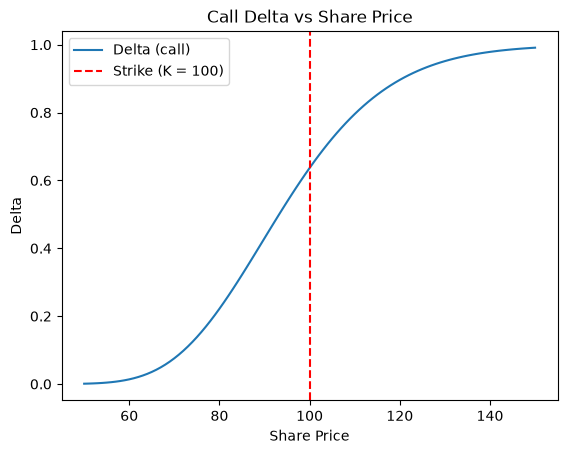

In [4]:
S_values = np.linspace(50, 150, 101)
dlt_prices = []
for S in S_values:
    dlt_prices.append(delta(S, 100, 1, 0.05, 0.2, 0.01))

plt.plot(S_values, dlt_prices, label="Delta (call)")
plt.axvline(100, linestyle="--", color="red", label="Strike (K = 100)")
plt.ylabel("Delta")
plt.xlabel("Share Price")
plt.title("Call Delta vs Share Price")
plt.legend()
plt.show()


In [5]:
def delta_formula(S, K, T, r, sigma, option_type):
    d1 = (np.log(S/K) + ((r + (sigma ** 2 / 2)) * T)) / (sigma * np.sqrt(T))
    if option_type == "call":
        return norm.cdf(d1)
    elif option_type == "put":
        return -norm.cdf(-d1)
    else:
        raise ValueError("Option type must be either call or put")
formula_deltas = []
for S in S_values:
    formula_deltas.append(delta_formula(S, 100, 1, 0.05, 0.2, "call"))


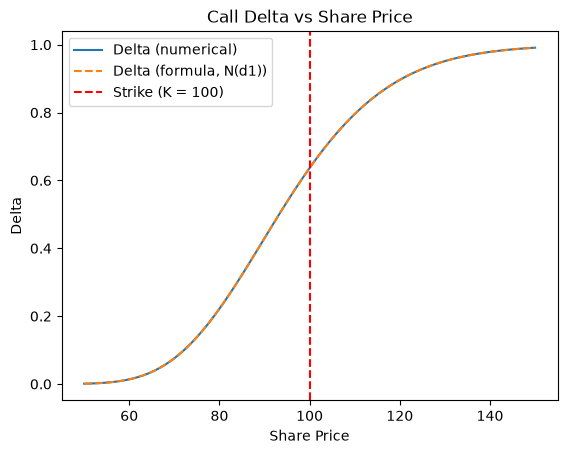

In [6]:
plt.plot(S_values, dlt_prices, label="Delta (numerical)")
plt.plot(S_values, formula_deltas, linestyle="--", label="Delta (formula, N(d1))")
plt.axvline(100, linestyle="--", color="red", label="Strike (K = 100)")
plt.ylabel("Delta")
plt.xlabel("Share Price")
plt.title("Call Delta vs Share Price")
plt.legend()
plt.show()

## Vega

37.52098305590792


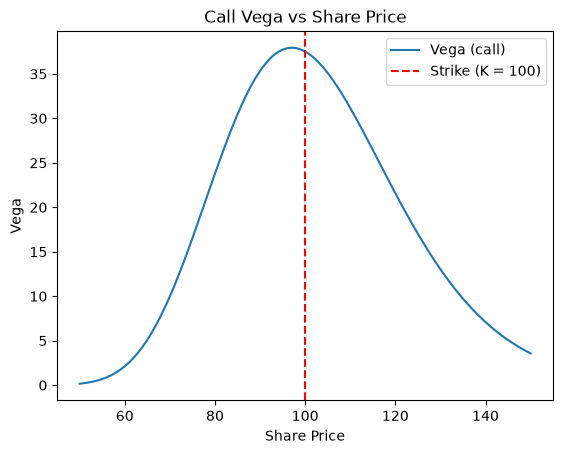

In [9]:
def vega(S, K, T, r, sigma, h):
    price_up = black_scholes(S, K, T, r, sigma + h, "call")
    price_down = black_scholes(S, K, T, r, sigma - h, "call")
    return (price_up - price_down) / (2 * h)

print(vega(100, 100, 1, 0.05, 0.2, 0.01))

S_values = np.linspace(50, 150, 101)
vga_prices = []
for S in S_values:
    vga_prices.append(vega(S, 100, 1, 0.05, 0.2, 0.01))

plt.plot(S_values, vga_prices, label="Vega (call)")
plt.axvline(100, linestyle="--", color="red", label="Strike (K = 100)")
plt.ylabel("Vega")
plt.xlabel("Share Price")
plt.title("Call Vega vs Share Price")
plt.legend()
plt.show()

## Theta

-6.414077196225776


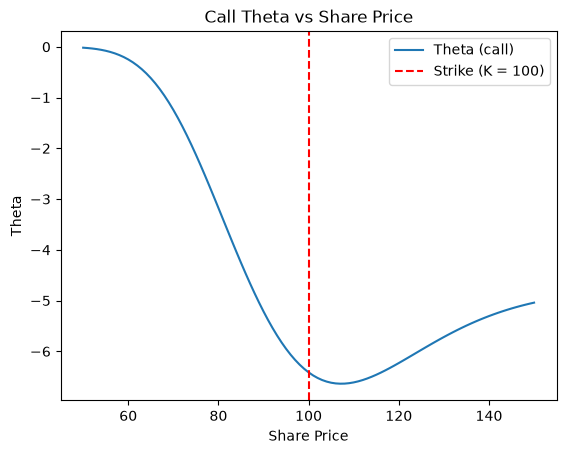

In [13]:
def theta(S, K, T, r, sigma, h):
    price_up = black_scholes(S, K, T + h, r, sigma, "call")
    price_down = black_scholes(S, K, T - h, r, sigma, "call")
    return -(price_up - price_down) / (2 * h)

print(theta(100, 100, 1, 0.05, 0.2, 0.01))

S_values = np.linspace(50, 150, 101)
tha_prices = []
for S in S_values:
    tha_prices.append(theta(S, 100, 1, 0.05, 0.2, 0.01))

plt.plot(S_values, tha_prices, label="Theta (call)")
plt.axvline(100, linestyle="--", color="red", label="Strike (K = 100)")
plt.ylabel("Theta")
plt.xlabel("Share Price")
plt.title("Call Theta vs Share Price")
plt.legend()
plt.show()

## Gamma

In [ ]:
def gamma(S, K, T, r, sigma, h):
    delta_up = delta(S + h, K, T, r, sigma, h)
    delta_down = delta(S - h, K, T, r, sigma, h)
    return (delta_up - delta_down) / (2 * h)

print(gamma(100, 100, 1, 0.05, 0.2, 0.01))

S_values = np.linspace(50, 150, 101)
gammas = []
for S in S_values:
    gammas.append(gamma(S, 100, 1, 0.05, 0.2, 0.01))
plt.plot(S_values, gammas, label="Gamma (call)")
plt.axvline(100, linestyle="--", color="red", label="Strike (K = 100)")
plt.ylabel("Gamma")
plt.xlabel("Share Price")
plt.title("Call Gamma vs Share Price")
plt.legend()
plt.show()


0.018762016438245155


TypeError: gamma() takes 6 positional arguments but 7 were given